## 44. Program - 2 - Finding Minima of the Function: SciPy Library

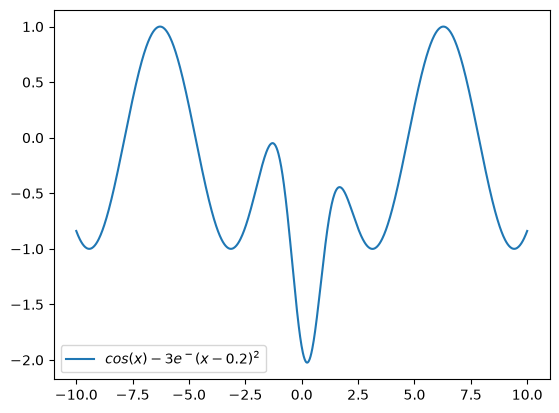

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fmin

def f(x):
    return np.cos(x) - 3*np.exp(-(x-0.2) ** 2)

in_x = 1 # starting initial guess

x = np.linspace(-10,10,1000)
plt.plot(x,f(x),label='$cos(x)-3e^-(x-0.2)^2$')
plt.legend()
plt.show()

Optimization terminated successfully.
         Current function value: -2.023866
         Iterations: 16
         Function evaluations: 32
value of x at which function in minimum [0.23964844]


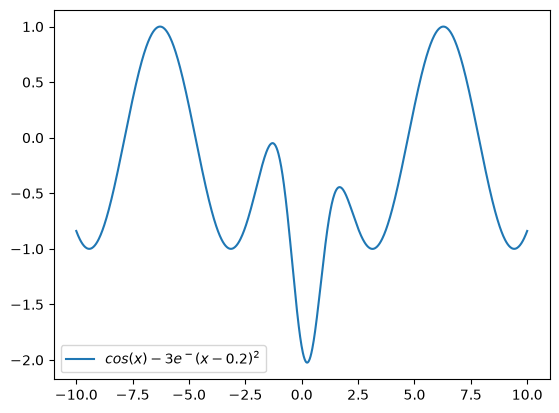

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fmin

def f(x):
    return np.cos(x) - 3*np.exp(-(x-0.2) ** 2)

in_x = 1 # starting initial guess

min_x = fmin(f,in_x)

print("value of x at which function in minimum", min_x)

x = np.linspace(-10,10,1000)
plt.plot(x,f(x),label='$cos(x)-3e^-(x-0.2)^2$')
plt.legend()
plt.show()

Optimization terminated successfully.
         Current function value: -2.023866
         Iterations: 16
         Function evaluations: 32
Optimization terminated successfully.
         Current function value: -1.000529
         Iterations: 16
         Function evaluations: 32
Optimization terminated successfully.
         Current function value: -1.000000
         Iterations: 17
         Function evaluations: 34


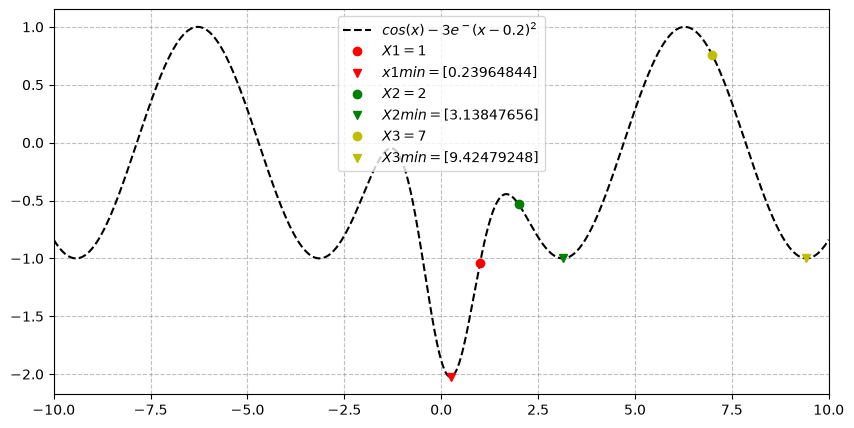

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fmin

def f(x):
    return np.cos(x) - 3*np.exp(-(x-0.2) ** 2)


in_x1 = 1 # starting initial guess
min_x1= fmin(f,in_x1)

in_x2 = 2
min_x2= fmin(f,in_x2)

in_x3 = 7
min_x3= fmin(f,in_x3)

plt.figure(figsize=(10,5))
x = np.linspace(-10,10,1000)

#plt.plot(x,f(x),label='$cos(x)-3e^-(x-0.2)^2$')
plt.plot(x,f(x),color = 'black',linestyle = '--',label='$cos(x) - 3e^-(x-0.2)^2$') # function curve

plt.plot(in_x1,f(in_x1),'or',label='$X1={}$'.format(in_x1))
plt.plot(min_x1,f(min_x1),'vr',label='$x1min={}$'.format(min_x1))

plt.plot(in_x2,f(in_x2),'og',label='$X2={}$'.format(in_x2))
plt.plot(min_x2,f(min_x2),'vg',label='$X2min={}$'.format(min_x2))

plt.plot(in_x3,f(in_x3),'oy',label='$X3={}$'.format(in_x3))
plt.plot(min_x3,f(min_x3),'vy',label='$X3min={}$'.format(min_x3))

plt.legend()
plt.grid(color='grey',linestyle='--',alpha=0.5)
plt.xlim(x[0],x[-1])
plt.show()

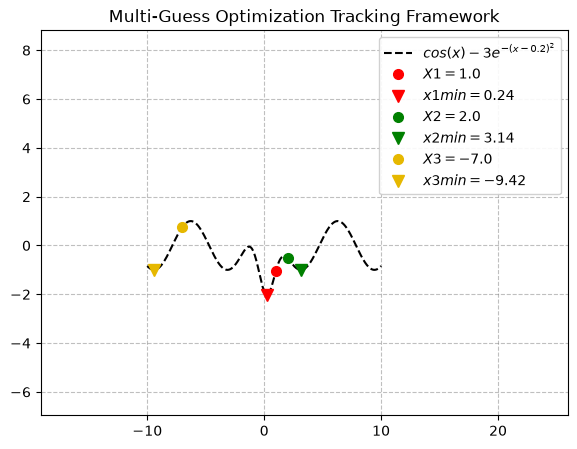

In [ ]:
#AI


import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fmin
import tkinter as tk

from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg, NavigationToolbar2Tk

def f(x):
    return np.cos(x) - 3*np.exp(-(x-0.2) ** 2)

class OptimizationApp:
    def __init__(self, root):
        self.root = root
        self.root.title("Interactive Optimization Visualizer")
        self.root.geometry("900x550")
        
        # --- Left Panel: Controls ---
        control_frame = tk.Frame(root, padx=15, pady=15, width=220, bg="#f5f5f5")
        control_frame.pack(side=tk.LEFT, fill=tk.Y)
        control_frame.pack_propagate(False)
        
        tk.Label(control_frame, text="Nelder-Mead Setup", font=('Helvetica', 12, 'bold'), bg="#f5f5f5").pack(pady=(0, 15))
        
        # Guess 1 Control
        tk.Label(control_frame, text="Initial Guess 1 (Red):", bg="#f5f5f5", anchor="w").pack(fill=tk.X)
        self.guess1_entry = tk.Entry(control_frame)
        self.guess1_entry.insert(0, "1.0")
        self.guess1_entry.pack(fill=tk.X, pady=(0, 10))
        
        # Guess 2 Control
        tk.Label(control_frame, text="Initial Guess 2 (Green):", bg="#f5f5f5", anchor="w").pack(fill=tk.X)
        self.guess2_entry = tk.Entry(control_frame)
        self.guess2_entry.insert(0, "2.0")
        self.guess2_entry.pack(fill=tk.X, pady=(0, 10))
        
        # Guess 3 Control
        tk.Label(control_frame, text="Initial Guess 3 (Yellow):", bg="#f5f5f5", anchor="w").pack(fill=tk.X)
        self.guess3_entry = tk.Entry(control_frame)
        self.guess3_entry.insert(0, "7.0")
        self.guess3_entry.pack(fill=tk.X, pady=(0, 15))
        
        # Run Button
        run_btn = tk.Button(control_frame, text="Run Optimization", command=self.update_plot, bg="#007ACC", fg="white", font=('Helvetica', 10, 'bold'))
        run_btn.pack(fill=tk.X, pady=(0, 15))
        
        # Status Outputs
        tk.Label(control_frame, text="Optimized Results:", font=('Helvetica', 10, 'bold'), bg="#f5f5f5", anchor="w").pack(fill=tk.X)
        
        self.res1_label = tk.Label(control_frame, text="x1 min: ---\nf(x1): ---", justify=tk.LEFT, fg="#d9534f", bg="#f5f5f5", font=('Courier', 9))
        self.res1_label.pack(anchor=tk.W, pady=5)
        
        self.res2_label = tk.Label(control_frame, text="x2 min: ---\nf(x2): ---", justify=tk.LEFT, fg="#5cb85c", bg="#f5f5f5", font=('Courier', 9))
        self.res2_label.pack(anchor=tk.W, pady=5)
        
        self.res3_label = tk.Label(control_frame, text="x3 min: ---\nf(x3): ---", justify=tk.LEFT, fg="#f0ad4e", bg="#f5f5f5", font=('Courier', 9))
        self.res3_label.pack(anchor=tk.W, pady=5)
        
        # --- Right Panel: Canvas Plot Window ---
        self.plot_frame = tk.Frame(root, bg="white")
        self.plot_frame.pack(side=tk.RIGHT, fill=tk.BOTH, expand=True)
        
        self.x_vals = np.linspace(-10, 10, 1000)
        
        self.fig, self.ax = plt.subplots(figsize=(6, 4.5))
        self.canvas = FigureCanvasTkAgg(self.fig, master=self.plot_frame)
        
        # Toolbar positioning element
        self.toolbar = NavigationToolbar2Tk(self.canvas, self.plot_frame)
        self.toolbar.update()
        
        self.canvas.get_tk_widget().pack(side=tk.TOP, fill=tk.BOTH, expand=True)
        
        self.update_plot()

    def optimize_and_draw(self, entry_widget, label_widget, color_code, label_prefix):
        try:
            in_x = float(entry_widget.get())
            min_x = float(fmin(f, in_x, disp=False)[0])
            f_min = f(min_x)
            
            label_widget.config(text=f"{label_prefix} min: {min_x:.3f}\nf({label_prefix}): {f_min:.3f}")
            
            # Map starting points and minimum markers to canvas matching original styling configurations
            self.ax.plot(in_x, f(in_x), 'o', color=color_code, markersize=7, label=f'${label_prefix.upper()}={in_x:.1f}$')
            self.ax.plot(min_x, f_min, 'v', color=color_code, markersize=9, label=f'${label_prefix}min={min_x:.2f}$')
        except ValueError:
            label_widget.config(text=f"{label_prefix} min: ERROR\nInvalid input")

    def update_plot(self):
        self.ax.clear()
        
        # Plot continuous base function mapping configuration
        self.ax.plot(self.x_vals, f(self.x_vals), color='black', linestyle='--', label='$cos(x) - 3e^{-(x-0.2)^2}$')
        
        # Run individual optimizations for each distinct guess field entry frame
        self.optimize_and_draw(self.guess1_entry, self.res1_label, 'red', 'x1')
        self.optimize_and_draw(self.guess2_entry, self.res2_label, 'green', 'x2')
        self.optimize_and_draw(self.guess3_entry, self.res3_label, '#e6b800', 'x3') # Darker yellow for plot visibility
        
        # Layout configurations match native original design schema rules
        self.ax.legend(loc='upper right', framealpha=0.9)
        self.ax.grid(color='grey', linestyle='--', alpha=0.5)
        self.ax.set_xlim(-10, 10)
        self.ax.set_ylim(-4.5, 2.5)
        self.ax.set_title("Multi-Guess Optimization Tracking Framework")
        
        self.canvas.draw()

if __name__ == "__main__":
    root = tk.Tk()
    app = OptimizationApp(root)
    root.mainloop()


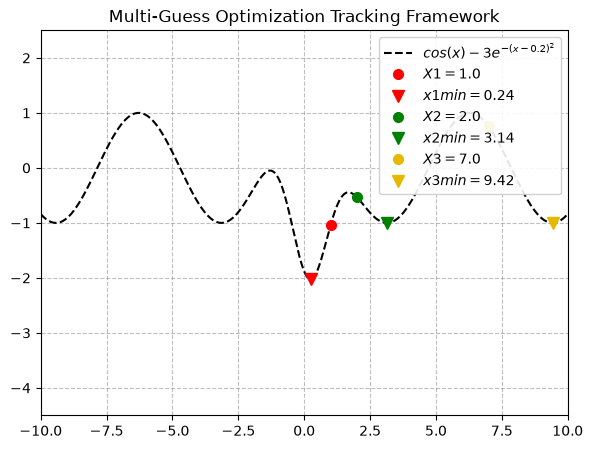

In [22]:
#AI

import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fmin
import tkinter as tk

# Backend adapter to embed Matplotlib plots seamlessly inside a Tkinter canvas user interface
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg, NavigationToolbar2Tk

# Define the mathematical objective function with multiple local minima and one global minimum
def f(x):
    return np.cos(x) - 3 * np.exp(-(x - 0.2) ** 2)

class OptimizationApp:
    def __init__(self, root):
        self.root = root
        self.root.title("Interactive Optimization Visualizer")
        self.root.geometry("900x550")
        
        # =========================================================================
        # --- Left Panel: Control Framework (Configuration Sidebar) ---
        # =========================================================================
        # Set up a fixed-width sidebar frame with a light background to group all input parameters
        control_frame = tk.Frame(root, padx=15, pady=15, width=220, bg="#f5f5f5")
        control_frame.pack(side=tk.LEFT, fill=tk.Y)
        control_frame.pack_propagate(False)  # Enforce structural width limits explicitly
        
        tk.Label(control_frame, text="Nelder-Mead Setup", font=('Helvetica', 12, 'bold'), bg="#f5f5f5").pack(pady=(0, 15))
        
        # --- Entry Field Configurations for Starting Points ---
        # Input framework for Initial Guess 1
        tk.Label(control_frame, text="Initial Guess 1 (Red):", bg="#f5f5f5", anchor="w").pack(fill=tk.X)
        self.guess1_entry = tk.Entry(control_frame)
        self.guess1_entry.insert(0, "1.0")
        self.guess1_entry.pack(fill=tk.X, pady=(0, 10))
        
        # Input framework for Initial Guess 2
        tk.Label(control_frame, text="Initial Guess 2 (Green):", bg="#f5f5f5", anchor="w").pack(fill=tk.X)
        self.guess2_entry = tk.Entry(control_frame)
        self.guess2_entry.insert(0, "2.0")
        self.guess2_entry.pack(fill=tk.X, pady=(0, 10))
        
        # Input framework for Initial Guess 3
        tk.Label(control_frame, text="Initial Guess 3 (Yellow):", bg="#f5f5f5", anchor="w").pack(fill=tk.X)
        self.guess3_entry = tk.Entry(control_frame)
        self.guess3_entry.insert(0, "7.0")
        self.guess3_entry.pack(fill=tk.X, pady=(0, 15))
        
        # --- Execution Interface Trigger ---
        # Button linking direct window actions to the plot calculation and updates
        run_btn = tk.Button(control_frame, text="Run Optimization", command=self.update_plot, bg="#007ACC", fg="white", font=('Helvetica', 10, 'bold'))
        run_btn.pack(fill=tk.X, pady=(0, 15))
        
        # --- Readout Dashboards (Numeric Outputs) ---
        tk.Label(control_frame, text="Optimized Results:", font=('Helvetica', 10, 'bold'), bg="#f5f5f5", anchor="w").pack(fill=tk.X)
        
        # Labels to host dynamic numerical coordinate calculations using a clean, monospaced font
        self.res1_label = tk.Label(control_frame, text="x1 min: ---\nf(x1): ---", justify=tk.LEFT, fg="#d9534f", bg="#f5f5f5", font=('Courier', 9))
        self.res1_label.pack(anchor=tk.W, pady=5)
        
        self.res2_label = tk.Label(control_frame, text="x2 min: ---\nf(x2): ---", justify=tk.LEFT, fg="#5cb85c", bg="#f5f5f5", font=('Courier', 9))
        self.res2_label.pack(anchor=tk.W, pady=5)
        
        self.res3_label = tk.Label(control_frame, text="x3 min: ---\nf(x3): ---", justify=tk.LEFT, fg="#f0ad4e", bg="#f5f5f5", font=('Courier', 9))
        self.res3_label.pack(anchor=tk.W, pady=5)
        
        # =========================================================================
        # --- Right Panel: Canvas Plot Window (Data Visualization Area) ---
        # =========================================================================
        self.plot_frame = tk.Frame(root, bg="white")
        self.plot_frame.pack(side=tk.RIGHT, fill=tk.BOTH, expand=True)
        
        # Generate baseline domain array for evaluating and rendering the black function curve
        self.x_vals = np.linspace(-10, 10, 1000)
        
        # Establish the Matplotlib chart structure
        self.fig, self.ax = plt.subplots(figsize=(6, 4.5))
        self.canvas = FigureCanvasTkAgg(self.fig, master=self.plot_frame)
        
        # Embed interactive standard controls (Pan, Zoom, Save Figure) into the top application space
        self.toolbar = NavigationToolbar2Tk(self.canvas, self.plot_frame)
        self.toolbar.update()
        
        # Pack the drawing canvas inside the Tkinter graphic window layout
        self.canvas.get_tk_widget().pack(side=tk.TOP, fill=tk.BOTH, expand=True)
        
        # Trigger an initial render cycle upon initialization
        self.update_plot()

    def optimize_and_draw(self, entry_widget, label_widget, color_code, label_prefix):
        """Processes an individual text input, executes the Nelder-Mead algorithm,

        updates the corresponding text layout metrics, and plots the results.
        """
        try:
            # Parse numeric string input from entry component frame safely
            in_x = float(entry_widget.get())
            
            # Execute SciPy's Nelder-Mead simplex local optimizer algorithm
            # Added explicit index mapping [0] to reliably extract the float minimum coordinate scalar
            min_x = float(fmin(f, in_x, disp=False)[0])
            f_min = f(min_x)
            
            # Format and output computed localized optimization states to dashboard
            label_widget.config(text=f"{label_prefix} min: {min_x:.3f}\nf({label_prefix}): {f_min:.3f}")
            
            # Plot initial guess markers (Circles) and converged minimum markers (Triangles) to graph space
            self.ax.plot(in_x, f(in_x), 'o', color=color_code, markersize=7, label=f'${label_prefix.upper()}={in_x:.1f}$')
            self.ax.plot(min_x, f_min, 'v', color=color_code, markersize=9, label=f'${label_prefix}min={min_x:.2f}$')
        except ValueError:
            # Handle text conversions exceptions gracefully to avoid runtime script failure
            label_widget.config(text=f"{label_prefix} min: ERROR\nInvalid input")

    def update_plot(self):
        """Resets the chart workspace axes, recalculates all data parameters,

        and forces a refreshed draw sweep across the Tkinter canvas panel window.
        """
        # Clear obsolete frame elements before refreshing state calculations
        self.ax.clear()
        
        # Draw the continuous base mathematical objective function curve
        self.ax.plot(self.x_vals, f(self.x_vals), color='black', linestyle='--', label='$cos(x) - 3e^{-(x-0.2)^2}$')
        
        # Run local optimization sweeps across each individual interactive guess entry block
        self.optimize_and_draw(self.guess1_entry, self.res1_label, 'red', 'x1')
        self.optimize_and_draw(self.guess2_entry, self.res2_label, 'green', 'x2')
        self.optimize_and_draw(self.guess3_entry, self.res3_label, '#e6b800', 'x3') # Darker yellow for high-contrast visibility
        
        # Re-apply standard layout configurations and design choices
        self.ax.legend(loc='upper right', framealpha=0.9)
        self.ax.grid(color='grey', linestyle='--', alpha=0.5)
        self.ax.set_xlim(-10, 10)
        self.ax.set_ylim(-4.5, 2.5)
        self.ax.set_title("Multi-Guess Optimization Tracking Framework")
        
        # Flush the updated figure onto the Tkinter frame canvas display surface
        self.canvas.draw()

if __name__ == "__main__":
    # Initialize the main execution loop for the desktop client shell
    root = tk.Tk()
    app = OptimizationApp(root)
    root.mainloop()
